# Diseñar un pool

**Objetivos**
1. Identificar productores, cola, workers, `Future` y punto de sincronización.
2. Medir tiempo y tamaño de cola con `max_workers` = 1, 2, 4, 8.
3. Construir un caso de deadlock y corregirlo.
4. Agregar timeout, cancelación y shutdown ordenado.
5. Discutir qué métrica usar: throughput, latencia o uso de CPU.

**Actividad sugerida:** simular 100 tareas con `sleep` aleatorio y 10 % de errores; recolectar resultados, errores y tiempos.




In [ ]:
import time, random, threading, statistics
from concurrent.futures import (ThreadPoolExecutor, as_completed, wait,
                                TimeoutError as FutureTimeout)
import matplotlib.pyplot as plt

def pct(data, p):
    data = sorted(data)
    return data[min(len(data) - 1, int(len(data) * p / 100))] if data else float("nan")

# Mini-ejemplo anotado
def tarea(x):
    time.sleep(0.1)
    return x * 2

with ThreadPoolExecutor(max_workers=2) as ex:          # crea los WORKERS y la COLA
    futuros = [ex.submit(tarea, i) for i in range(5)]  # PRODUCTOR: encola y recibe FUTURES
    for f in as_completed(futuros):                    # SINCRONIZACIÓN: espera a que terminen
        print("resultado:", f.result())
# al salir del `with` -> shutdown(wait=True): otro punto de sincronización


resultado: 0
resultado: 2
resultado: 4
resultado: 6
resultado: 8


## 2. Simulación: 100 tareas, `sleep` aleatorio, 10 % de errores
Cada tarea duerme entre 20 y 200 ms y falla con probabilidad 0.10. Se registran **resultados, errores y tiempos**, y un hilo monitor muestrea el **tamaño de la cola**.


In [ ]:
def simular(max_workers, n_tasks=100, muestreo=0.02):
    resultados, errores = {}, {}
    t_submit, t_inicio, t_fin = {}, {}, {}
    cola_muestras = []

    def tarea(i):
        t_inicio[i] = time.perf_counter()
        try:
            time.sleep(random.uniform(0.02, 0.2))
            if random.random() < 0.10:
                raise ValueError(f"fallo simulado en tarea {i}")
            return i * i
        finally:
            t_fin[i] = time.perf_counter()

    t0 = time.perf_counter()
    with ThreadPoolExecutor(max_workers=max_workers) as ex:
        parar = threading.Event()
        def monitor():
            while not parar.is_set():
                cola_muestras.append((time.perf_counter() - t0, ex._work_queue.qsize()))
                time.sleep(muestreo)
        mon = threading.Thread(target=monitor, daemon=True); mon.start()

        futuros = {}
        for i in range(n_tasks):
            t_submit[i] = time.perf_counter()
            futuros[ex.submit(tarea, i)] = i

        for f in as_completed(futuros):          # recolectar resultados Y errores
            i = futuros[f]
            try:
                resultados[i] = f.result()
            except Exception as e:
                errores[i] = repr(e)
        parar.set(); mon.join()
    total = time.perf_counter() - t0

    return dict(workers=max_workers, total=total, throughput=n_tasks / total,
                ok=len(resultados), err=len(errores), errores=errores,
                lat=[t_fin[i] - t_submit[i] for i in t_fin],       # incluye espera en cola
                servicio=[t_fin[i] - t_inicio[i] for i in t_fin],  # solo ejecución
                cola=cola_muestras)

datos = {}
for n in [1, 2, 4, 8]:
    r = simular(n); datos[n] = r
    print(f"max_workers={n}: total={r['total']:.1f}s  throughput={r['throughput']:.1f}/s  "
          f"ok={r['ok']} err={r['err']}  cola máx={max(q for _, q in r['cola'])}  "
          f"lat p50/p95={pct(r['lat'],50)*1000:.0f}/{pct(r['lat'],95)*1000:.0f} ms")


max_workers=1: total=11.2s  throughput=8.9/s  ok=92 err=8  cola máx=99  lat p50/p95=5420/10805 ms
max_workers=2: total=5.6s  throughput=17.9/s  ok=89 err=11  cola máx=98  lat p50/p95=2911/5344 ms
max_workers=4: total=3.0s  throughput=33.6/s  ok=97 err=3  cola máx=96  lat p50/p95=1589/2825 ms
max_workers=8: total=1.4s  throughput=69.9/s  ok=93 err=7  cola máx=92  lat p50/p95=659/1323 ms


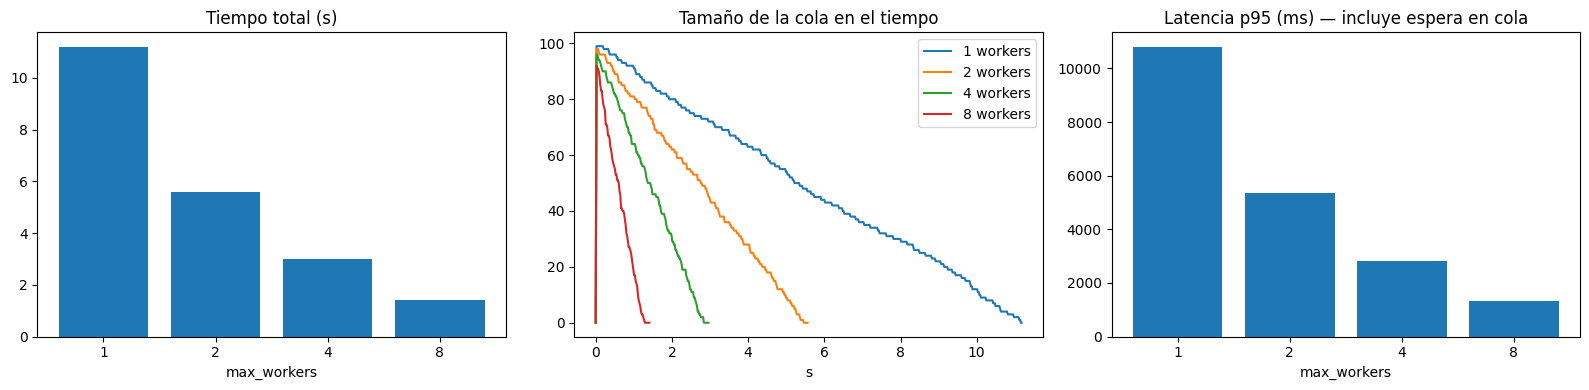

Ejemplo de errores recolectados (8 workers):
  tarea 24: ValueError('fallo simulado en tarea 24')
  tarea 39: ValueError('fallo simulado en tarea 39')
  tarea 36: ValueError('fallo simulado en tarea 36')
  tarea 42: ValueError('fallo simulado en tarea 42')
  tarea 56: ValueError('fallo simulado en tarea 56')


In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
ns = list(datos)
axs[0].bar([str(n) for n in ns], [datos[n]["total"] for n in ns])
axs[0].set_title("Tiempo total (s)"); axs[0].set_xlabel("max_workers")
for n in ns:
    t, q = zip(*datos[n]["cola"]); axs[1].plot(t, q, label=f"{n} workers")
axs[1].set_title("Tamaño de la cola en el tiempo"); axs[1].set_xlabel("s"); axs[1].legend()
axs[2].bar([str(n) for n in ns], [pct(datos[n]["lat"], 95) * 1000 for n in ns])
axs[2].set_title("Latencia p95 (ms) — incluye espera en cola"); axs[2].set_xlabel("max_workers")
plt.tight_layout(); plt.show()

print("Ejemplo de errores recolectados (8 workers):")
for i, e in list(datos[8]["errores"].items())[:5]:
    print(f"  tarea {i}: {e}")



## 3. Deadlock: el pool se espera a sí mismo



In [ ]:
def demo_deadlock():
    ex = ThreadPoolExecutor(max_workers=1)

    def interna():
        return "interna terminó"

    def externa():
        f = ex.submit(interna)               # se encola en el MISMO pool
        try:
            return f.result(timeout=1.0)     # se bloquea esperando
        except FutureTimeout:
            return                           #deadlock detectado

    resultado = ex.submit(externa).result()
    ex.shutdown(wait=True)
    return resultado

print(demo_deadlock())


None


In [ ]:
# Corrección A: pool separado para las subtareas
def fix_pool_separado():
    pool_externo = ThreadPoolExecutor(max_workers=1)
    pool_interno = ThreadPoolExecutor(max_workers=1)
    def interna(): return "interna terminó"
    def externa():
        return pool_interno.submit(interna).result(timeout=1.0)   # otro pool -> sí hay worker libre
    r = pool_externo.submit(externa).result()
    pool_externo.shutdown(); pool_interno.shutdown()
    return r

# Corrección B: sin bloquear dentro del pool (orquesta el hilo principal)
def fix_orquestar_afuera():
    with ThreadPoolExecutor(max_workers=1) as ex:
        paso1 = ex.submit(lambda: 21).result()          # el main espera, no un worker
        paso2 = ex.submit(lambda x: x * 2, paso1).result()
    return paso2

print("A:", fix_pool_separado())
print("B:", fix_orquestar_afuera())


A: interna terminó
B: 42


---
## 4. Timeout, cancelación y shutdown ordenado


In [ ]:
def tarea_cancelable(i, cancelar: threading.Event):
    for _ in range(10):                     # 10 pasos de 50 ms = 0.5 s de trabajo
        if cancelar.is_set():
            return ("abortada", i)          # cancelación cooperativa
        time.sleep(0.05)
    return ("ok", i)

def correr_con_deadline(n_tasks=100, workers=4, deadline=1.2):
    cancelar = threading.Event()
    ex = ThreadPoolExecutor(max_workers=workers)
    futs = [ex.submit(tarea_cancelable, i, cancelar) for i in range(n_tasks)]
    t0 = time.perf_counter()
    try:
        for f in as_completed(futs, timeout=deadline):   # TIMEOUT global
            pass
    except FutureTimeout:
        print(f" Deadline de {deadline}s alcanzado -> cancelando")
        cancelar.set()                                   # 1) señal a las que ya corren
        for f in futs: f.cancel()                        # 2) cancela las pendientes
    finally:
        ex.shutdown(wait=True, cancel_futures=True)      # 3) espera a las que están corriendo
    dur = time.perf_counter() - t0

    ok = abortadas = canceladas = 0
    for f in futs:
        if f.cancelled(): canceladas += 1
        else:
            estado, _ = f.result()
            ok += estado == "ok"; abortadas += estado == "abortada"
    print(f"Terminó en {dur:.2f}s | completadas={ok}  abortadas en ejecución={abortadas}  "
          f"canceladas antes de empezar={canceladas}")

correr_con_deadline()


 Deadline de 1.2s alcanzado -> cancelando
Terminó en 1.20s | completadas=8  abortadas en ejecución=4  canceladas antes de empezar=88


---
## 5. ¿Qué métrica usar en la práctica?

Cuando diseñamos o monitoreamos un pool de conexiones o de hilos, no existe una única métrica que sirva para todo. Dependiendo de la naturaleza de nuestro sistema, debemos poner el foco en distintos indicadores clave:

* **Throughput:** Nos dice cuánto trabajo real está procesando nuestro sistema por unidad de tiempo (por ejemplo, tareas por segundo). Es la métrica estrella cuando tenemos procesos por lotes (batch processing), crawlers o pipelines de datos (ETL), donde lo único que importa es terminar el volumen total de trabajo lo antes posible. La trampa aquí es que el throughput puede verse excelente mientras que, al mismo tiempo, la latencia de algunas tareas individuales se está disparando debido a la saturación.

* **Latencia:** Responde a cuánto tiempo le toma a una tarea individual completarse, y suele medirse en percentiles como el p50 (el caso típico) o el p95 y p99 (los casos más lentos). Es crucial en servicios interactivos o APIs donde hay un usuario esperando. Hay que tener mucho cuidado con dos cosas: primero, usar promedios suele ocultar el sufrimiento de los usuarios que caen en la 'cola larga' (los percentiles altos); segundo, medir el tiempo desde que se envía la tarea (`submit`) incluye la espera silenciosa en la cola del pool, no solo el tiempo activo de ejecución.

* **Uso de CPU:** Nos indica si nuestro cuello de botella está en la capacidad de cómputo de la máquina. Es fundamental para optimizar tareas intensivas en operaciones matemáticas o procesamiento de imágenes (CPU-bound) y nos ayuda a decidir si nos conviene usar hilos o procesos. La trampa más común es ver un uso de CPU bajísimo (cercano al 0%) y asumir que el sistema está holgado, cuando en realidad está completamente saturado porque todos los hilos están bloqueados esperando respuestas de red o de base de datos (I/O-bound).


In [ ]:
def cpu_tarea(_):
    s = 0
    for k in range(1_500_000):
        s += k * k
    return s

def medir(nombre, fn, n_tasks, workers):
    c0, w0 = time.process_time(), time.perf_counter()
    with ThreadPoolExecutor(max_workers=workers) as ex:
        list(ex.map(fn, range(n_tasks)))
    wall = time.perf_counter() - w0
    cpu = time.process_time() - c0
    print(f"{nombre:<10} workers={workers}: pared={wall:5.2f}s  CPU={cpu:5.2f}s  "
          f"uso CPU≈{cpu / wall * 100:5.0f}%  throughput={n_tasks / wall:5.1f}/s")

io_tarea = lambda _: time.sleep(0.1)

for w in [1, 4]:
    medir("I/O-bound", io_tarea, 40, w)
for w in [1, 4]:
    medir("CPU-bound", cpu_tarea, 16, w)


I/O-bound  workers=1: pared= 4.05s  CPU= 0.01s  uso CPU≈    0%  throughput=  9.9/s
I/O-bound  workers=4: pared= 1.00s  CPU= 0.01s  uso CPU≈    1%  throughput= 39.9/s
CPU-bound  workers=1: pared= 2.17s  CPU= 2.16s  uso CPU≈  100%  throughput=  7.4/s
CPU-bound  workers=4: pared= 2.27s  CPU= 2.28s  uso CPU≈  100%  throughput=  7.0/s


Al analizar los resultados anteriores, queda claro el comportamiento de cada carga: en las tareas I/O-bound, añadir más hilos nos permite multiplicar casi por cuatro el rendimiento (throughput) sin apenas alterar el uso de la CPU. En cambio, con las tareas CPU-bound, meter más hilos no mejora las cosas debido a las limitaciones del GIL en Python; de hecho, la CPU se satura por completo en un solo núcleo y los tiempos de procesamiento pueden incluso empeorar por la sobrecarga de administración.

## 6. Ideas clave

- **La anatomía del pool:** Diseñar un pool no es solo lanzar hilos. Requiere entender la relación dinámica entre el productor que genera el trabajo, la cola que contiene las tareas en espera, los workers que las ejecutan y los objetos `Future` que actúan como "contratos" de sincronización. Saber identificar cada parte es lo que nos permite prevenir bloqueos catastróficos.

- **El límite del paralelismo:** Incrementar el número de trabajadores (`max_workers`) reducirá los tiempos de espera y el tamaño de la cola únicamente si nuestras tareas pasan tiempo bloqueadas esperando factores externos (I/O). En algún momento, siempre nos toparemos con la ley de rendimientos decrecientes.

- **Deadlock:** Un deadlock ocurre de forma muy sencilla si una tarea que ya está corriendo dentro del pool se queda esperando el resultado de otra subtarea que aún está en la cola esperando por un hilo libre. Para solucionarlo, nunca bloquear un hilo del pool esperando a otra tarea del mismo pool; es mucho mejor delegar esa orquestación al hilo principal o utilizar pools de ejecución separados para jerarquías distintas de tareas.

- **Timeout:** Cuando una tarea expira por tiempo, el pool solo deja de *esperarla*, pero el hilo sigue trabajando en segundo plano. Para un control real del sistema, necesitamos implementar mecanismos de cancelación cooperativa (usando señales o eventos compartidos) junto con un apagado (`shutdown`) ordenado y controlado del pool.

